# SMART VINEYARD
## PHÂN TÍCH KHÁM PHÁ DATA (EDA)

### 1. Giới thiệu
file jupyter này thực hiện phần phân tích khám phá bộ dữ liệu GVLiD

### 2. Mục tiêu
- Khám phá cấu trúc dataset
- Phân tích phân bố các loại bệnh trên lá nho
- Trực quan hóa hình ảnh
- Phân tích các tập dữ liệu (metadata.json)
- Kiểm tra dữ liệu thiếu và dữ liệu có dấu hiệu bất thường

### 3. Các lớp dữ liệu
- Healthy: Lá khỏe mạnh
- Black rot: Bị thối đen
- Esca: bị bệnh esca
- Leaf Blight: bệnh cháy lá

**1. IMPORT THƯ VIỆN**

In [5]:
#Import thư viện xử lý dữ liệu
import numpy as np
import pandas as pd

#Import thư viện trực quan hóa
import matplotlib.pyplot as plt
import seaborn as sns

#Import thư viện xử lý ảnh
from PIL import Image

#Thư viện xử lý file
import os
from pathlib import Path

#Cấu hình hiển thị biểu đồ
sns.set_theme(style ="whitegrid")
plt.rcParams["figure.figsize"] = (10,6)

print("Đã import thư viện thành công")

Đã import thư viện thành công


**2. KẾT NỐI DATASET**

In [6]:
BASE_DIR = Path.cwd()

DATASET_DIR = Path(r"D:\DataMining26\Smart-Vineyard\Dataset\GVLiD GrapeVine Leaf identification of the Disease\DATASET") #Đổi đường dẫn cho hợp lý khi chạy file

if DATASET_DIR.exists():
    print("Đã tìm thấy dataset !")
    print("Đường dẫn: ", DATASET_DIR)
else:
    print("Không tìm thấy dataset !")
    print("Đường dẫn hiện tại: ", DATASET_DIR)

Đã tìm thấy dataset !
Đường dẫn:  D:\DataMining26\Smart-Vineyard\Dataset\GVLiD GrapeVine Leaf identification of the Disease\DATASET



 - Tìm thấy dataset GVLiD ở đường dẫn cục bộ `D:\DataMining26\...\DATASET`.
 - Đường dẫn đang được gán cứng theo máy cá nhân, nên khi chạy trên máy khác cần đổi `DATASET_DIR`.

**3. KIỂM TRA CẤU TRÚC THƯ MỤC**

In [7]:
for item in DATASET_DIR.iterdir():
    if item.is_dir():
        print("[THƯ MỤC]", item.name)
    else:
        print("[TỆP]", item.name)

[THƯ MỤC] Black rot
[THƯ MỤC] esca
[THƯ MỤC] healthy
[THƯ MỤC] leaf blight
[TỆP] metadata.json
[TỆP] readme.md




- Thư mục gốc có 4 thư mục lớp: `Black rot`, `esca`, `healthy`, `leaf blight`, cùng 2 tệp `metadata.json` và `readme.md`.
- Cấu trúc khớp với 4 lớp dữ liệu ở phần giới thiệu.

**4.ĐỌC METADATA**

In [8]:
# Tìm tất cả file JSON trong Dataset
json_files = list(DATASET_DIR.rglob("*.json"))

print("SỐ FILE JSON:", len(json_files))
print("=" * 40)

for file in json_files:
    print("Tên file:", file.name)
    print("Đường dẫn:", file)

SỐ FILE JSON: 1
Tên file: metadata.json
Đường dẫn: D:\DataMining26\Smart-Vineyard\Dataset\GVLiD GrapeVine Leaf identification of the Disease\DATASET\metadata.json


In [9]:
import json

# Chọn file JSON đầu tiên
if json_files:
    json_path = json_files[0]

    with open(json_path, "r", encoding="utf-8") as f:
        metadata = json.load(f)

    print("Đọc JSON thành công!")
else:
    print("Không tìm thấy file JSON!")

Đọc JSON thành công!


In [10]:
#Kiểm tra kiểu dl json
print("Kiểu dữ liệu: ", type(metadata))

# Hiển thị nd
print(json.dumps(metadata, indent = 4, ensure_ascii=False)[:5000])

Kiểu dữ liệu:  <class 'list'>
[
    {
        "Sr_No": 1,
        "Location": {
            "Vineyard": "Vineyard_22",
            "GPS": {
                "Latitude": 18.785238,
                "Longitude": 73.994949
            }
        },
        "Environmental_Conditions": {
            "Time_of_Capture": "Afternoon",
            "Lighting": "Overcast",
            "Weather": "Humid"
        },
        "Plant_Health_Status": "Diseased",
        "Disease_Type": "Black Rot",
        "Device_Specifications": {
            "Device_Name": "Redmi Note 10 5G",
            "Sensor": "Sony IMX 582 1/2rr",
            "OS": "Android"
        }
    },
    {
        "Sr_No": 2,
        "Location": {
            "Vineyard": "Vineyard_28",
            "GPS": {
                "Latitude": 18.731029,
                "Longitude": 73.977206
            }
        },
        "Environmental_Conditions": {
            "Time_of_Capture": "Afternoon",
            "Lighting": "Natural sunlight",
         

- `metadata` là một `list`, mỗi phần tử là một bản ghi (dict lồng nhau) gồm: `Location` (Vineyard + GPS), `Environmental_Conditions`, `Plant_Health_Status`, `Disease_Type`, `Device_Specifications`.
- Các bản ghi đầu (Sr_No 1, 2, 3...) đều là `Black Rot`, chụp bằng Redmi Note 10 5G trên Android.

| STT | Thuộc tính | Ý nghĩa |
|---|---|---|
| 1 | `Sr_No` | Số thứ tự của bản ghi |
| 2 | `Location.Vineyard` | Mã định danh vườn nho nơi thu thập mẫu |
| 3 | `Location.GPS.Latitude` | Tọa độ vĩ độ của vị trí thu thập mẫu |
| 4 | `Location.GPS.Longitude` | Tọa độ kinh độ của vị trí thu thập mẫu |
| 5 | `Environmental_Conditions.Time_of_Capture` | Thời điểm chụp ảnh |
| 6 | `Environmental_Conditions.Lighting` | Điều kiện ánh sáng tại thời điểm chụp |
| 7 | `Environmental_Conditions.Weather` | Điều kiện thời tiết tại thời điểm chụp |
| 8 | `Plant_Health_Status` | Tình trạng sức khỏe của cây nho |
| 9 | `Disease_Type` | Loại bệnh được ghi nhận trên mẫu cây |
| 10 | `Device_Specifications.Device_Name` | Tên thiết bị được sử dụng để chụp ảnh |
| 11 | `Device_Specifications.Sensor` | Thông tin cảm biến hình ảnh của thiết bị |
| 12 | `Device_Specifications.OS` | Hệ điều hành của thiết bị thu thập dữ liệu |

**5.TỔNG QUAN DỮ LIỆU**

Chuyển đổi thành String

In [11]:
# Đọc file JSON
with open(json_path, "r", encoding="utf-8") as file:
    metadata = json.load(file)

# Chuyển JSON thành DataFrame
df_metadata = pd.json_normalize(metadata)

# Hiển thị 5 dòng đầu tiên
display(df_metadata.head())

,Sr_No,Plant_Health_Status,Disease_Type,Location.Vineyard,Location.GPS.Latitude,Location.GPS.Longitude,Environmental_Conditions.Time_of_Capture,Environmental_Conditions.Lighting,Environmental_Conditions.Weather,Device_Specifications.Device_Name,Device_Specifications.Sensor,Device_Specifications.OS
0,1,Diseased,Black Rot,Vineyard_22,18.785238,73.994949,Afternoon,Overcast,Humid,Redmi Note 10 5G,Sony IMX 582 1/2rr,Android
1,2,Diseased,Black Rot,Vineyard_28,18.731029,73.977206,Afternoon,Natural sunlight,Humid,Redmi Note 10 5G,Sony IMX 582 1/2rr,Android
2,3,Diseased,Black Rot,Vineyard_14,18.802297,74.027516,Afternoon,Partly cloudy,Humid,Redmi Note 10 5G,Sony IMX 582 1/2rr,Android
3,4,Diseased,Black Rot,Vineyard_20,18.775820,74.000550,Morning,Overcast,Humid,Redmi Note 10 5G,Sony IMX 582 1/2rr,Android
4,5,Diseased,Black Rot,Vineyard_8,18.790580,74.002429,Evening,Partly cloudy,Clear,Redmi Note 10 5G,Sony IMX 582 1/2rr,Android


Tổng quan data

In [12]:
# Kích thước dữ liệu
print("Số dòng:", df_metadata.shape[0])
print("Số cột:", df_metadata.shape[1])

# Danh sách thuộc tính
print("\nDanh sách thuộc tính:")
print(df_metadata.columns.tolist())

# Kiểu dữ liệu
print("\nKiểu dữ liệu:")
print(df_metadata.dtypes)

Số dòng: 3478
Số cột: 12

Danh sách thuộc tính:
['Sr_No', 'Plant_Health_Status', 'Disease_Type', 'Location.Vineyard', 'Location.GPS.Latitude', 'Location.GPS.Longitude', 'Environmental_Conditions.Time_of_Capture', 'Environmental_Conditions.Lighting', 'Environmental_Conditions.Weather', 'Device_Specifications.Device_Name', 'Device_Specifications.Sensor', 'Device_Specifications.OS']

Kiểu dữ liệu:
Sr_No                                         int64
Plant_Health_Status                             str
Disease_Type                                    str
Location.Vineyard                               str
Location.GPS.Latitude                       float64
Location.GPS.Longitude                      float64
Environmental_Conditions.Time_of_Capture        str
Environmental_Conditions.Lighting               str
Environmental_Conditions.Weather                str
Device_Specifications.Device_Name               str
Device_Specifications.Sensor                    str
Device_Specifications.OS      

**6. PHÂN BỐ NHÃN**

In [13]:
label_counts = df_metadata["Disease_Type"].value_counts()

label_percent = df_metadata["Disease_Type"].value_counts(normalize=True) * 100

label_summary = pd.DataFrame({
    "So_luong": label_counts,
    "Ty_le (%)": label_percent.round(2)
})

display(label_summary)

,So_luong,Ty_le (%)
Disease_Type,,
Healthy,1109,31.89
Esca,888,25.53
Black Rot,809,23.26
Leaf Blight,672,19.32



- Dữ liệu **mất cân bằng nhẹ**: lớp lớn nhất (Healthy) gấp khoảng 1,65 lần lớp nhỏ nhất (Leaf Blight).
- Chưa quá nghiêm trọng, nhưng nên dùng stratified split, class weight hoặc augmentation cho lớp ít mẫu.

**7.KIỂM TRA CHẤT LƯỢNG DATA**

Thống kê dữ liệu bị thiếu

,Missing Values,Missing (%)
Sr_No,0,0.0
Plant_Health_Status,0,0.0
Disease_Type,0,0.0
Location.Vineyard,0,0.0
Location.GPS.Latitude,0,0.0
Location.GPS.Longitude,0,0.0
Environmental_Conditions.Time_of_Capture,0,0.0
Environmental_Conditions.Lighting,0,0.0
Environmental_Conditions.Weather,0,0.0
Device_Specifications.Device_Name,0,0.0


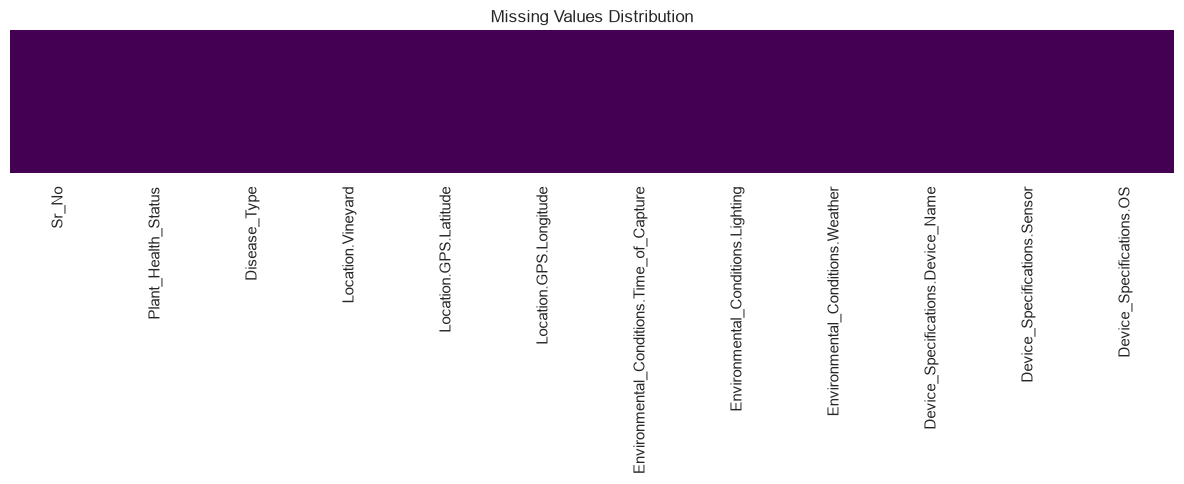

In [14]:
missing_report = pd.DataFrame({
    "Missing Values": df_metadata.isnull().sum(),
    "Missing (%)": (
        df_metadata.isnull().sum() / len(df_metadata) * 100
    ).round(2)
})

display(missing_report)

# Trực quan hóa
plt.figure(figsize=(12, 5))
sns.heatmap(
    df_metadata.isnull(),
    cbar=False,
    cmap="viridis",
    yticklabels=False
)
plt.title("Missing Values Distribution")
plt.tight_layout()
plt.show()


- **Không có giá trị thiếu** ở cả 12 cột (0%), heatmap cho thấy toàn một màu.

Thống kê dữ liệu trùng

In [15]:
duplicate_report = pd.DataFrame({
    "Metric": [
        "Completely Duplicated Records",
        "Duplicated Sr_No",
        "Duplicated GPS Coordinates"
    ],
    "Count": [
        df_metadata.duplicated().sum(),
        df_metadata["Sr_No"].duplicated().sum(),
        df_metadata.duplicated(
            subset=[
                "Location.GPS.Latitude",
                "Location.GPS.Longitude"
            ]
        ).sum()
    ]
})

display(duplicate_report)

# Hiển thị các bản ghi trùng hoàn toàn
display(
    df_metadata[
        df_metadata.duplicated(keep=False)
    ].head(10)
)

,Metric,Count
0,Completely Duplicated Records,0
1,Duplicated Sr_No,0
2,Duplicated GPS Coordinates,3450


,Sr_No,Plant_Health_Status,Disease_Type,Location.Vineyard,Location.GPS.Latitude,Location.GPS.Longitude,Environmental_Conditions.Time_of_Capture,Environmental_Conditions.Lighting,Environmental_Conditions.Weather,Device_Specifications.Device_Name,Device_Specifications.Sensor,Device_Specifications.OS




- Không có bản ghi trùng hoàn toàn (0) và không trùng `Sr_No` (0).
- Có 3.450 dòng trùng tọa độ GPS, tương ứng 3.478 − 28. Đây là **hiện tượng bình thường**, vì mỗi vườn dùng chung một tọa độ (xem nhận xét phần GPS), không phải lỗi dữ liệu.

Hiển thị các bảng ghi có vấn đề

In [16]:
# Kiểm tra kiểu dữ liệu
display(df_metadata.dtypes)

# Kiểm tra các nhãn phân loại
categorical_columns = [
    "Disease_Type",
    "Plant_Health_Status",
    "Environmental_Conditions.Weather",
    "Environmental_Conditions.Lighting",
    "Environmental_Conditions.Time_of_Capture"
]

for col in categorical_columns:
    print(f"\n{col}:")
    display(df_metadata[col].value_counts(dropna=False))

# Kiểm tra giá trị dạng chuỗi rỗng
empty_values = (
    df_metadata.select_dtypes(include="object")
    .apply(lambda col: col.astype("string").str.strip().eq("").sum())
)

print("\nSố lượng chuỗi rỗng:")
display(empty_values)

Sr_No                                         int64
Plant_Health_Status                             str
Disease_Type                                    str
Location.Vineyard                               str
Location.GPS.Latitude                       float64
Location.GPS.Longitude                      float64
Environmental_Conditions.Time_of_Capture        str
Environmental_Conditions.Lighting               str
Environmental_Conditions.Weather                str
Device_Specifications.Device_Name               str
Device_Specifications.Sensor                    str
Device_Specifications.OS                        str
dtype: object


Disease_Type:


Disease_Type
Healthy        1109
Esca            888
Black Rot       809
Leaf Blight     672
Name: count, dtype: int64


Plant_Health_Status:


Plant_Health_Status
Diseased    2369
Healthy     1109
Name: count, dtype: int64


Environmental_Conditions.Weather:


... (4 outputs left out)

Environmental_Conditions.Time_of_Capture
Morning      1185
Afternoon    1168
Evening      1125
Name: count, dtype: int64


Số lượng chuỗi rỗng:


C:\Users\Khang Nguyen\AppData\Local\Temp\ipykernel_32696\2916569941.py:19: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df_metadata.select_dtypes(include="object")


Plant_Health_Status                         0
Disease_Type                                0
Location.Vineyard                           0
Environmental_Conditions.Time_of_Capture    0
Environmental_Conditions.Lighting           0
Environmental_Conditions.Weather            0
Device_Specifications.Device_Name           0
Device_Specifications.Sensor                0
Device_Specifications.OS                    0
dtype: int64

- Kiểu dữ liệu đúng như mong đợi.
- Các cột phân loại sạch: `Disease_Type` có 4 giá trị, `Plant_Health_Status` có 2, và 3 cột môi trường có 3 giá trị mỗi cột. Không có lỗi chính tả, không có biến thể viết hoa/thường.
- Không có chuỗi rỗng ở cột nào.

Kiểm tra tính hợp lệ của GPS

In [17]:
# Chuyển GPS về dạng số
lat = pd.to_numeric(
    df_metadata["Location.GPS.Latitude"],
    errors="coerce"
)

lon = pd.to_numeric(
    df_metadata["Location.GPS.Longitude"],
    errors="coerce"
)

# Kiểm tra tọa độ ngoài phạm vi hợp lệ
invalid_gps = (
    lat.notna() & lon.notna() &
    (~lat.between(-90, 90) | ~lon.between(-180, 180))
)

# Kiểm tra GPS không chuyển được sang dạng số
invalid_format = (
    (df_metadata["Location.GPS.Latitude"].notna() & lat.isna()) |
    (df_metadata["Location.GPS.Longitude"].notna() & lon.isna())
)

print("GPS ngoài phạm vi hợp lệ:", invalid_gps.sum())
print("GPS sai định dạng:", invalid_format.sum())

display(df_metadata[invalid_gps | invalid_format])

GPS ngoài phạm vi hợp lệ: 0
GPS sai định dạng: 0


,Sr_No,Plant_Health_Status,Disease_Type,Location.Vineyard,Location.GPS.Latitude,Location.GPS.Longitude,Environmental_Conditions.Time_of_Capture,Environmental_Conditions.Lighting,Environmental_Conditions.Weather,Device_Specifications.Device_Name,Device_Specifications.Sensor,Device_Specifications.OS


> - Không có tọa độ nào ngoài phạm vi hợp lệ (0) và không có GPS sai định dạng (0).

Kiểm tra tính toàn vẹn ảnh

In [18]:
# Thu thập danh sách ảnh
image_extensions = [".jpg", ".jpeg", ".png", ".bmp", ".webp"]

image_files = [
    f for f in DATASET_DIR.rglob("*")
    if f.is_file() and f.suffix.lower() in image_extensions
]

corrupted_images = []
invalid_images = []
image_info = []

for file_path in image_files:
    try:
        with Image.open(file_path) as img:
            img.verify()

        with Image.open(file_path) as img:
            width, height = img.size
            image_format = img.format
            mode = img.mode

            if width <= 0 or height <= 0:
                invalid_images.append(str(file_path))

            image_info.append({
                "File": str(file_path),
                "Width": width,
                "Height": height,
                "Format": image_format,
                "Mode": mode
            })

    except Exception:
        corrupted_images.append(str(file_path))

df_image_info = pd.DataFrame(image_info)

print("Total Images:", len(image_files))
print("Corrupted Images:", len(corrupted_images))
print("Invalid Images:", len(invalid_images))

display(df_image_info.head())

Total Images: 3477
Corrupted Images: 0
Invalid Images: 0


,File,Width,Height,Format,Mode
0,D:\DataMining26\Smart-Vineyard\Dataset\GVLiD G...,1080,1080,JPEG,RGB
1,D:\DataMining26\Smart-Vineyard\Dataset\GVLiD G...,1080,1080,JPEG,RGB
2,D:\DataMining26\Smart-Vineyard\Dataset\GVLiD G...,1080,1080,JPEG,RGB
3,D:\DataMining26\Smart-Vineyard\Dataset\GVLiD G...,1080,1080,JPEG,RGB
4,D:\DataMining26\Smart-Vineyard\Dataset\GVLiD G...,1080,1080,JPEG,RGB



- Quét được **3.477 ảnh**; 0 ảnh hỏng, 0 ảnh có kích thước không hợp lệ.
- 5 dòng đầu đều là JPEG, RGB, 1080×1080 (thống kê đầy đủ ở cell bên dưới).

Kiểm tra liên kết ảnh và metadata

In [19]:
# Thống kê số lượng ảnh và metadata
print("Total Metadata Records:", len(df_metadata))
print("Total Image Files:", len(image_files))

# Thống kê ảnh theo định dạng
print("\nImage Formats:")
display(df_image_info["Format"].value_counts())

# Thống kê kích thước ảnh
print("\nImage Dimensions:")
display(
    df_image_info.groupby(
        ["Width", "Height"]
    ).size().reset_index(name="Count")
    .sort_values("Count", ascending=False)
    .head(10)
)

Total Metadata Records: 3478
Total Image Files: 3477

Image Formats:


Format
JPEG    3477
Name: count, dtype: int64


Image Dimensions:


,Width,Height,Count
0,1080,1080,3477


-  Metadata có **3.478** bản ghi nhưng chỉ có **3.477** ảnh, **lệch 1**. Có thể thiếu 1 ảnh hoặc thừa 1 bản ghi, cần xác định cụ thể.
- Toàn bộ ảnh đều là JPEG và cùng kích thước **1080×1080** (3.477/3.477), nên không cần xử lý đồng bộ kích thước từ đầu.
- Cell này mới chỉ so sánh tổng số lượng, chưa đối chiếu từng file với từng bản ghi (metadata không có tên file, chỉ có `Sr_No`) và chưa đếm số ảnh theo từng thư mục lớp. Nên bổ sung bước này để biết chính xác bản ghi hoặc ảnh nào bị lệch.

Đối chiếu số ảnh theo thư mục lớp với metadata

In [20]:
import re

# Thư mục lớp của từng ảnh (thư mục con cấp 1 trong DATASET)
df_image_info["Class_Folder"] = df_image_info["File"].apply(
    lambda p: Path(p).relative_to(DATASET_DIR).parts[0]
)

# So sánh số ảnh theo thư mục lớp với số bản ghi theo Disease_Type
img_per_class = df_image_info["Class_Folder"].str.lower().value_counts().rename("So_anh")
meta_per_class = df_metadata["Disease_Type"].str.lower().value_counts().rename("So_ban_ghi")

class_compare = pd.concat([img_per_class, meta_per_class], axis=1).fillna(0).astype(int)
class_compare["Chenh_lech (ghi - anh)"] = class_compare["So_ban_ghi"] - class_compare["So_anh"]
display(class_compare)

lech = class_compare.index[class_compare["Chenh_lech (ghi - anh)"] != 0].tolist()
print("Lớp bị lệch:", lech if lech else "Không có")

,So_anh,So_ban_ghi,Chenh_lech (ghi - anh)
healthy,1109,1109,0
esca,888,888,0
black rot,808,809,1
leaf blight,672,672,0


Lớp bị lệch: ['black rot']


- Lệch nằm ở lớp **Black Rot**: 809 bản ghi nhưng chỉ có 808 ảnh. Ba lớp còn lại khớp hoàn toàn (Healthy 1.109, Esca 888, Leaf Blight 672).
- Vậy chênh lệch 3.478 bản ghi so với 3.477 ảnh là do **thiếu 1 ảnh Black Rot**, không phải lệch rải rác ở nhiều lớp.

Đối chiếu từng ảnh với bản ghi metadata

In [21]:
# Xem quy ước đặt tên file ở từng thư mục lớp
for folder, group in df_image_info.groupby("Class_Folder"):
    print(folder, "->", [Path(p).name for p in group["File"].head(3)])


# Lấy số thứ tự ở cuối tên file (vd: "xxx_123.jpg" -> 123)
def last_number(path):
    nums = re.findall(r"\d+", Path(path).stem)
    return int(nums[-1]) if nums else None


df_image_info["Img_No"] = df_image_info["File"].apply(last_number)
print("\nẢnh không trích được số thứ tự:", df_image_info["Img_No"].isna().sum())

# Đối chiếu từng lớp: số trong tên file có khớp với Sr_No (hoặc 1..n) của lớp đó không
rows = []
for folder, group in df_image_info.groupby("Class_Folder"):
    records = df_metadata[df_metadata["Disease_Type"].str.lower() == folder.lower()]
    img_ids = set(group["Img_No"].dropna().astype(int))
    expected = {
        "Sr_No": set(records["Sr_No"]),
        "1..n": set(range(1, len(records) + 1)),
    }
    # Chọn cách đánh số khớp nhiều nhất với tên file
    best = max(expected, key=lambda k: len(img_ids & expected[k]))
    thieu = sorted(expected[best] - img_ids)
    thua = sorted(img_ids - expected[best])
    rows.append({
        "Class_Folder": folder,
        "Cach_danh_so": best,
        "So_ban_ghi_thieu_anh": len(thieu),
        "Vi_du_thieu_anh": thieu[:10],
        "So_anh_thua": len(thua),
        "Vi_du_anh_thua": thua[:10],
    })

display(pd.DataFrame(rows))

Black rot -> ['black rot001.jpg', 'black rot002.jpg', 'black rot003.jpg']
esca -> ['esca001.jpg', 'esca002.jpg', 'esca003.jpg']
healthy -> ['healthy001.jpg', 'healthy002.jpg', 'healthy003.jpg']
leaf blight -> ['leaf blight001.jpg', 'leaf blight002.jpg', 'leaf blight003.jpg']

Ảnh không trích được số thứ tự: 0


,Class_Folder,Cach_danh_so,So_ban_ghi_thieu_anh,Vi_du_thieu_anh,So_anh_thua,Vi_du_anh_thua
0,Black rot,Sr_No,2,"[20, 809]",0,[]
1,esca,1..n,0,[],0,[]
2,healthy,1..n,0,[],0,[]
3,leaf blight,1..n,0,[],0,[]


- Tên file có dạng `<tên lớp><số thứ tự>.jpg` (ví dụ `black rot001.jpg`, `esca001.jpg`), nên trích được số thứ tự của cả 3.477 ảnh.
- Healthy, Esca và Leaf Blight khớp hoàn toàn với metadata: không thiếu ảnh, không thừa ảnh (ảnh đánh số 1..n theo từng lớp).
- Black Rot đánh số theo `Sr_No` và có **2 bản ghi không có ảnh: Sr_No 20 và 809**, không có ảnh thừa.
- Chỗ chưa khớp: lớp này có 808 ảnh nhưng chỉ thiếu 2 số, nghĩa là chỉ có 807 số thứ tự khác nhau. Như vậy có 1 ảnh bị **trùng số** với ảnh khác (có thể là file copy hoặc đặt tên lạ, ví dụ có thêm hậu tố như `(1)`). Đây là suy luận từ số liệu, cần lọc các `Img_No` bị trùng trong thư mục `Black rot` để xác nhận.

**HƯỚNG XỬ LÝ**

In [22]:
bl = df_image_info[
    df_image_info["Class_Folder"].str.lower() == "black rot"
].copy()

In [23]:
import hashlib

def md5(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

# df là DataFrame chứa cột Img_No và File
dup = bl[bl["Img_No"] == 31].copy()

dup["Ten_file"] = dup["File"].apply(lambda p: Path(p).name)
dup["MD5"] = dup["File"].apply(md5)

display(dup[["Ten_file", "MD5"]])

,Ten_file,MD5
29,black rot031.jpg,e956d299b80ec98c4cb26c0556da819f
807,mega dataset (31) - Copy - Copy - Copy.jpg,f9842245a80e11875f278315b091c333


In [24]:
# 2. Loại file không đúng quy ước tên (không xóa file trên ổ đĩa)
valid_name = df_image_info["File"].apply(
    lambda p: re.fullmatch(r"(black rot|esca|healthy|leaf blight)\d+", Path(p).stem.lower()) is not None
)
print("File sai quy ước tên:", (~valid_name).sum())
display(df_image_info.loc[~valid_name, "File"].apply(lambda p: Path(p).name))

df_image_clean = df_image_info[valid_name].copy()
print("Số ảnh hợp lệ:", len(df_image_clean))      # kỳ vọng 3476

File sai quy ước tên: 1


807    mega dataset (31) - Copy - Copy - Copy.jpg
Name: File, dtype: str

Số ảnh hợp lệ: 3476


In [25]:
# 3. Bỏ 2 bản ghi không có ảnh (Sr_No 20 và 809)
df_metadata_clean = df_metadata[~df_metadata["Sr_No"].isin([20, 809])].copy()
print("Số bản ghi sau khi làm sạch:", len(df_metadata_clean))   # kỳ vọng 3476
print(df_metadata_clean["Disease_Type"].value_counts())

Số bản ghi sau khi làm sạch: 3476
Disease_Type
Healthy        1109
Esca            888
Black Rot       807
Leaf Blight     672
Name: count, dtype: int64


**Kiểm tra ảnh trùng lặp (MD5)**

Ảnh trùng lặp là vấn đề chất lượng dữ liệu cần phát hiện ngay ở bước EDA vì nó ảnh hưởng đến:
- **Các con số EDA:** tỷ lệ lớp, số mẫu mỗi vườn và các kiểm định thống kê đều bị tính lặp cả những ảnh giống hệt nhau.
- **Huấn luyện mô hình:** nếu chia train/val/test ngẫu nhiên, bản sao của cùng một ảnh nằm ở cả train và test làm kết quả đánh giá **cao ảo**.

Ở đây chỉ **phát hiện và đo mức độ**. Việc xử lý (giữ 1 ảnh đại diện mỗi nhóm, hoặc chia train/test theo nhóm trùng) được thực hiện ở bước **03_Image_Preprocessing**.

Phương pháp: so mã MD5 của nội dung file, nên chỉ bắt được ảnh **giống hệt từng byte**. Ảnh bị nén lại, resize hoặc cắt nhẹ sẽ không bị phát hiện. Chỉ xét 3.476 ảnh hợp lệ (đã loại file sai quy ước tên ở bước trước).

In [26]:
import hashlib
import time

def md5_of(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

LABEL_MAP = {
    "black rot": "Black Rot",
    "esca": "Esca",
    "healthy": "Healthy",
    "leaf blight": "Leaf Blight",
}

# Chỉ xét ảnh hợp lệ (df_image_clean)
df_dup = df_image_clean[["File", "Class_Folder", "Img_No"]].copy()
df_dup["Image_Name"] = df_dup["File"].apply(lambda p: Path(p).name)
df_dup["Disease_Type"] = df_dup["Class_Folder"].str.lower().map(LABEL_MAP)

t0 = time.time()
df_dup["MD5"] = df_dup["File"].apply(md5_of)
print(f"Đã tính MD5 cho {len(df_dup)} ảnh trong {time.time() - t0:.0f}s")

Đã tính MD5 cho 3476 ảnh trong 3s


In [27]:
group_size = df_dup.groupby("MD5").size()
dup_groups = group_size[group_size > 1]

n_images = len(df_dup)
n_in_dup_groups = int(dup_groups.sum())        # số ảnh nằm trong nhóm có >= 2 ảnh giống nhau
n_extra = int((dup_groups - 1).sum())          # số ảnh dư nếu mỗi nhóm chỉ giữ 1 ảnh

print("Tổng số ảnh hợp lệ                         :", n_images)
print("Số ảnh khác nhau (MD5 duy nhất)            :", df_dup["MD5"].nunique())
print(f"Số ảnh nằm trong nhóm trùng                : {n_in_dup_groups} ({n_in_dup_groups / n_images:.1%})")
print("Số nhóm trùng                              :", len(dup_groups))
print(f"Số ảnh dư (nếu mỗi nhóm giữ 1 ảnh)         : {n_extra} ({n_extra / n_images:.1%})")

print("\nKích thước nhóm trùng (số ảnh giống nhau trong 1 nhóm):")
display(
    dup_groups.value_counts().sort_index()
    .rename("So_nhom").rename_axis("So_anh_trong_nhom").to_frame()
)

Tổng số ảnh hợp lệ                         : 3476
Số ảnh khác nhau (MD5 duy nhất)            : 2409
Số ảnh nằm trong nhóm trùng                : 1513 (43.5%)
Số nhóm trùng                              : 446
Số ảnh dư (nếu mỗi nhóm giữ 1 ảnh)         : 1067 (30.7%)

Kích thước nhóm trùng (số ảnh giống nhau trong 1 nhóm):


,So_nhom
So_anh_trong_nhom,
2,342
4,5
7,1
8,94
9,2
16,2


,Tong_anh,Anh_trong_nhom_trung,Anh_du,Ty_le_anh_du (%)
Disease_Type,,,,
Healthy,1109,32,16,1.4
Esca,888,2,2,0.2
Black Rot,807,807,708,87.7
Leaf Blight,672,672,341,50.7


Số nhóm trùng nằm ở NHIỀU lớp khác nhau (mâu thuẫn nhãn): 2
Số nhóm trùng nằm trong CÙNG một lớp                    : 444


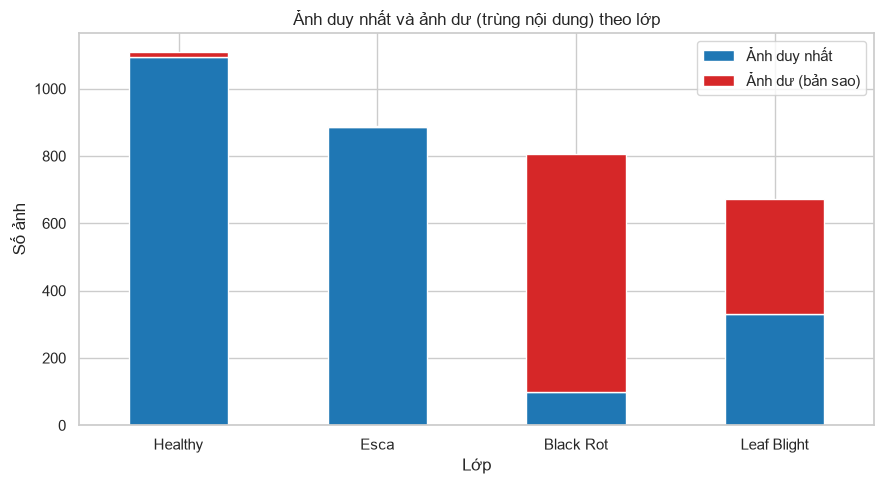


Ví dụ 5 nhóm trùng lớn nhất:
- 16 ảnh: ['black rot121.jpg', 'black rot122.jpg', 'black rot123.jpg', 'black rot124.jpg', 'black rot125.jpg', 'black rot126.jpg'] ...
- 16 ảnh: ['black rot179.jpg', 'black rot180.jpg', 'black rot181.jpg', 'black rot182.jpg', 'black rot183.jpg', 'black rot184.jpg'] ...
- 9 ảnh: ['black rot801.jpg', 'black rot802.jpg', 'black rot803.jpg', 'black rot804.jpg', 'black rot805.jpg', 'black rot806.jpg'] ...
- 9 ảnh: ['black rot793.jpg', 'black rot794.jpg', 'black rot795.jpg', 'black rot796.jpg', 'black rot797.jpg', 'black rot798.jpg'] ...
- 8 ảnh: ['black rot025.jpg', 'black rot026.jpg', 'black rot027.jpg', 'black rot028.jpg', 'black rot029.jpg', 'black rot030.jpg'] ...


In [28]:
dup_mask = df_dup["MD5"].isin(dup_groups.index)
extra_mask = df_dup.duplicated("MD5", keep="first")

# Mức độ trùng theo lớp
by_class = pd.concat(
    [
        df_dup["Disease_Type"].value_counts().rename("Tong_anh"),
        df_dup[dup_mask]["Disease_Type"].value_counts().rename("Anh_trong_nhom_trung"),
        df_dup[extra_mask]["Disease_Type"].value_counts().rename("Anh_du"),
    ],
    axis=1
).fillna(0).astype(int)
by_class["Ty_le_anh_du (%)"] = (by_class["Anh_du"] / by_class["Tong_anh"] * 100).round(1)
display(by_class)

# Nhóm trùng nằm ở nhiều lớp khác nhau = mâu thuẫn nhãn
classes_per_group = df_dup[dup_mask].groupby("MD5")["Disease_Type"].nunique()
n_conflict = int((classes_per_group > 1).sum())
print("Số nhóm trùng nằm ở NHIỀU lớp khác nhau (mâu thuẫn nhãn):", n_conflict)
print("Số nhóm trùng nằm trong CÙNG một lớp                    :", int((classes_per_group == 1).sum()))

# Biểu đồ: ảnh duy nhất và ảnh dư theo lớp
plot_df = pd.DataFrame({
    "Ảnh duy nhất": by_class["Tong_anh"] - by_class["Anh_du"],
    "Ảnh dư (bản sao)": by_class["Anh_du"],
})
plot_df.plot(kind="bar", stacked=True, figsize=(9, 5), color=["tab:blue", "tab:red"])
plt.title("Ảnh duy nhất và ảnh dư (trùng nội dung) theo lớp")
plt.xlabel("Lớp"); plt.ylabel("Số ảnh"); plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Ví dụ một số nhóm trùng lớn nhất
print("\nVí dụ 5 nhóm trùng lớn nhất:")
for md5_key in dup_groups.sort_values(ascending=False).head(5).index:
    names = df_dup.loc[df_dup["MD5"] == md5_key, "Image_Name"].tolist()
    print(f"- {len(names)} ảnh: {names[:6]}{' ...' if len(names) > 6 else ''}")

**Ảnh trùng có cùng metadata không?**

Với mỗi nhóm trùng, so sánh metadata của các ảnh trong nhóm (vườn, thời tiết, ánh sáng, thời điểm chụp). Cần file `image_metadata.json` được tạo ở bước **02_DataMatching**.
- **Trùng hoàn toàn:** ảnh và metadata đều giống nhau, đây là bản ghi bị nhân bản.
- **Cùng ảnh nhưng metadata khác nhau:** một ảnh gắn với nhiều vườn hoặc điều kiện chụp. Nếu loại này nhiều thì cần xem lại quy tắc ghép ảnh với metadata, vì nó ảnh hưởng đến cả phân tích ở mục 8.

In [29]:
# File tạo ở 02_DataMatching (đổi đường dẫn nếu bạn lưu ở chỗ khác)
MATCHED_JSON = DATASET_DIR.parents[2] / "outputs" / "processed" / "image_metadata.json"

meta_cols = [
    "Location.Vineyard",
    "Environmental_Conditions.Weather",
    "Environmental_Conditions.Lighting",
    "Environmental_Conditions.Time_of_Capture",
]

if MATCHED_JSON.exists():
    with open(MATCHED_JSON, "r", encoding="utf-8") as f:
        df_m = pd.DataFrame(json.load(f))

    d = df_dup.merge(df_m[["Image_Name", "Sr_No"] + meta_cols], on="Image_Name", how="left")
    print("Ảnh không tìm thấy metadata tương ứng:", int(d["Sr_No"].isna().sum()))

    d_dup = d[d["MD5"].isin(dup_groups.index)]
    group_meta = d_dup.groupby("MD5")[meta_cols].nunique()
    same_meta = (group_meta == 1).all(axis=1)

    print("\nSố nhóm trùng có metadata GIỐNG HỆT nhau   :", int(same_meta.sum()))
    print("Số nhóm trùng có metadata KHÁC nhau        :", int((~same_meta).sum()))
    print("\nSố nhóm có giá trị khác nhau theo từng thuộc tính:")
    display((group_meta > 1).sum().rename("So_nhom_khac_nhau").to_frame())

    # Ảnh hưởng đến số mẫu mỗi vườn nếu chỉ giữ 1 ảnh mỗi nhóm
    before = d["Location.Vineyard"].value_counts()
    after = d.drop_duplicates("MD5")["Location.Vineyard"].value_counts()
    print(f"\nSố mẫu mỗi vườn: trước {before.min()}–{before.max()}, sau khi loại trùng {after.min()}–{after.max()}")
else:
    print("Chưa có file:", MATCHED_JSON)
    print("-> Chạy 02_DataMatching trước, hoặc đổi MATCHED_JSON cho đúng đường dẫn. Bỏ qua phần này.")

Ảnh không tìm thấy metadata tương ứng: 0

Số nhóm trùng có metadata GIỐNG HỆT nhau   : 1
Số nhóm trùng có metadata KHÁC nhau        : 445

Số nhóm có giá trị khác nhau theo từng thuộc tính:


,So_nhom_khac_nhau
Location.Vineyard,427
Environmental_Conditions.Weather,327
Environmental_Conditions.Lighting,334
Environmental_Conditions.Time_of_Capture,331



Số mẫu mỗi vườn: trước 107–144, sau khi loại trùng 68–103


In [30]:
# Ảnh hưởng của ảnh trùng lên phân bố nhãn (chỉ giữ ảnh đầu tiên của mỗi nhóm)
df_unique = df_dup.drop_duplicates("MD5", keep="first")

impact = pd.concat(
    [
        df_dup["Disease_Type"].value_counts().rename("Truoc"),
        df_unique["Disease_Type"].value_counts().rename("Sau_loai_trung"),
    ],
    axis=1
)
impact["Ty_le_truoc (%)"] = (impact["Truoc"] / impact["Truoc"].sum() * 100).round(2)
impact["Ty_le_sau (%)"] = (impact["Sau_loai_trung"] / impact["Sau_loai_trung"].sum() * 100).round(2)
display(impact)
print(f"Tổng: {impact['Truoc'].sum()} -> {impact['Sau_loai_trung'].sum()} ảnh")

,Truoc,Sau_loai_trung,Ty_le_truoc (%),Ty_le_sau (%)
Disease_Type,,,,
Healthy,1109,1093,31.90,45.37
Esca,888,886,25.55,36.78
Black Rot,807,99,23.22,4.11
Leaf Blight,672,331,19.33,13.74


Tổng: 3476 -> 2409 ảnh


**Hướng xử lý (thực hiện ở 03_Image_Preprocessing)**
- Gán mã nhóm trùng (`MD5`, `Dup_Group_Id`) cho từng ảnh và đánh dấu ảnh dư.
- Nhóm trùng nằm ở nhiều lớp (mâu thuẫn nhãn): loại toàn bộ ảnh trong nhóm.
- Các nhóm còn lại: giữ 1 ảnh đại diện mỗi nhóm, hoặc giữ tất cả nhưng **chia train/val/test theo nhóm trùng** để bản sao không rơi vào cả train và test.
- Sau khi xử lý, chạy lại các bảng phân bố ở mục 6 và mục 8 trên tập đã loại trùng để so sánh.

**8.PHÂN TÍCH METADATA**

8.1. Phân tích vị trí địa lý

In [31]:
# Thống kê số lượng mẫu theo từng vườn nho
vineyard_counts = (
    df_metadata["Location.Vineyard"]
    .value_counts()
    .sort_index(
        key=lambda x: x.str.extract(r'(\d+)')[0].astype(int)
    )
)

display(vineyard_counts)

print(
    "Tổng số vườn nho:",
    df_metadata["Location.Vineyard"].nunique()
)

Location.Vineyard
Vineyard_1     109
Vineyard_2     122
Vineyard_3     123
Vineyard_4     126
Vineyard_5     127
Vineyard_6     129
Vineyard_7     107
Vineyard_8     130
Vineyard_9     125
Vineyard_10    125
Vineyard_11    133
Vineyard_12    134
Vineyard_13    117
Vineyard_14    117
Vineyard_15    125
Vineyard_16    109
Vineyard_17    123
Vineyard_18    122
Vineyard_19    112
Vineyard_20    108
Vineyard_21    120
Vineyard_22    131
Vineyard_23    135
Vineyard_24    144
Vineyard_25    134
Vineyard_26    142
Vineyard_27    125
Vineyard_28    124
Name: count, dtype: int64

Tổng số vườn nho: 28


- Có **28 vườn nho** (Vineyard_1 → Vineyard_28), mỗi vườn có từ 107 mẫu (Vineyard_7) đến 144 mẫu (Vineyard_24).
- Số mẫu giữa các vườn khá đồng đều, không có vườn nào chiếm ưu thế.

8.2 Phân tích điều kiện môi trường

In [32]:
# Các thuộc tính môi trường cần khảo sát
environment_columns = [
    "Environmental_Conditions.Time_of_Capture",
    "Environmental_Conditions.Lighting",
    "Environmental_Conditions.Weather"
]

# Thống kê từng thuộc tính
for col in environment_columns:
    print("\n", "=" * 50)
    print("Thuộc tính:", col)

    display(df_metadata[col].value_counts(dropna=False))



Thuộc tính: Environmental_Conditions.Time_of_Capture


Environmental_Conditions.Time_of_Capture
Morning      1185
Afternoon    1168
Evening      1125
Name: count, dtype: int64


Thuộc tính: Environmental_Conditions.Lighting


Environmental_Conditions.Lighting
Natural sunlight    1175
Overcast            1164
Partly cloudy       1139
Name: count, dtype: int64


Thuộc tính: Environmental_Conditions.Weather


Environmental_Conditions.Weather
Windy    1177
Humid    1160
Clear    1141
Name: count, dtype: int64



> - Cả 3 thuộc tính môi trường đều chia gần đều thành 3 nhóm, không có giá trị thiếu:
>   - Thời điểm chụp: Morning 1.185 / Afternoon 1.168 / Evening 1.125
>   - Ánh sáng: Natural sunlight 1.175 / Overcast 1.164 / Partly cloudy 1.139
>   - Thời tiết: Windy 1.177 / Humid 1.160 / Clear 1.141
> - Mỗi nhóm chiếm khoảng 1/3, chênh lệch tối đa khoảng 5%. Dữ liệu được thu thập rất cân bằng về điều kiện chụp, nên ảnh hưởng của điều kiện chụp lên mô hình có thể sẽ không lớn.

8.3 Phân tích tình trạng sức khỏe

In [33]:
health_counts = df_metadata[
    "Plant_Health_Status"
].value_counts(dropna=False)

display(health_counts)

Plant_Health_Status
Diseased    2369
Healthy     1109
Name: count, dtype: int64


> - `Diseased` 2.369 mẫu (68,11%) và `Healthy` 1.109 mẫu (31,89%).
> - Số mẫu `Healthy` trùng khớp với lớp `Healthy` trong `Disease_Type` (1.109), nghĩa là `Plant_Health_Status` được suy ra trực tiếp từ `Disease_Type`. Không nên dùng cột này làm feature cùng với nhãn bệnh, vì sẽ bị rò rỉ nhãn (data leakage).

8.4 Phân tích thiết bị thu thập data

In [34]:
device_counts = df_metadata[
    "Device_Specifications.Device_Name"
].value_counts(dropna=False)

display(device_counts)

Device_Specifications.Device_Name
Redmi Note 10 5G    3478
Name: count, dtype: int64

> - Toàn bộ 3.478 mẫu đều chụp bằng **một thiết bị duy nhất**: Redmi Note 10 5G.
> - Không có sự khác biệt giữa các thiết bị, nên cột này không có giá trị phân tích. Ưu điểm là không có thiên lệch do nhiều loại camera khác nhau.

8.5 Phân tích mối liên hệ giữa các thuộc tính
- Do có nhiều thuộc tính khác nhau nên số lượng liên hệ khá dày đặc. Ở đây sẽ tập trung các mối liên kết chính:
```text
1. thời tiết và tình trạng cây (Weather x Plant_Health_Status)
2. ánh sáng và tình trạng cây (Lightning x Plant_Health_Status)
3. thời điểm và tình trạng cây (Time_of_Capture x Plant_Health_Status)
4. phân bố các loại bệnh ở các vườn (Vineyard x Disease_Type)
5. phân bố theo điều kiện thời tiết (Weather x Disease_Type)
6. GPS x Disease_Type
```

8.5.1 thời tiết và tình trạng cây (Weather x Plant_Health_Status)

Plant_Health_Status,Diseased,Healthy
Environmental_Conditions.Weather,,
Clear,780,361
Humid,794,366
Windy,795,382


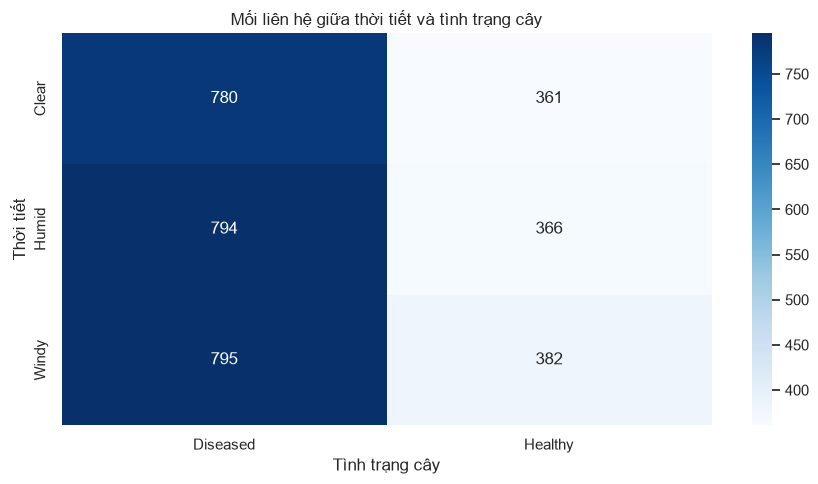

In [35]:
weather_health = pd.crosstab(
    df_metadata["Environmental_Conditions.Weather"],
    df_metadata["Plant_Health_Status"]
)
display(weather_health)

plt.figure(figsize=(9, 5))

sns.heatmap(
    weather_health,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Mối liên hệ giữa thời tiết và tình trạng cây")
plt.xlabel("Tình trạng cây")
plt.ylabel("Thời tiết")

plt.tight_layout()
plt.show()

> - Tỷ lệ cây bệnh gần như bằng nhau ở mọi loại thời tiết: Clear 780/1141 (≈68,4%), Humid 794/1160 (≈68,4%), Windy 795/1177 (≈67,5%).
> - **Thời tiết gần như không liên quan đến tình trạng cây** trong dữ liệu này.

8.5.2 ánh sáng và tình trạng cây (Lightning x Plant_Health_Status)

Plant_Health_Status,Diseased,Healthy
Environmental_Conditions.Lighting,,
Natural sunlight,804,371
Overcast,798,366
Partly cloudy,767,372


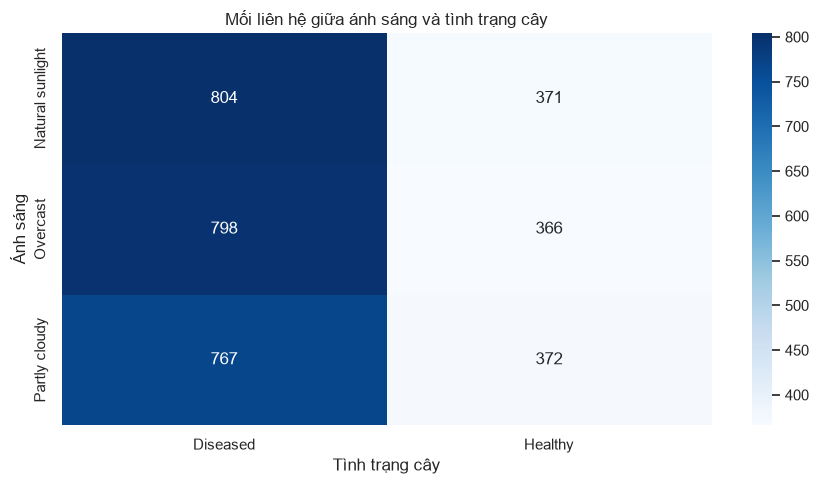

In [36]:
lighting_health = pd.crosstab(
    df_metadata["Environmental_Conditions.Lighting"],
    df_metadata["Plant_Health_Status"]
)
display(lighting_health)

plt.figure(figsize=(9, 5))

sns.heatmap(
    lighting_health,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Mối liên hệ giữa ánh sáng và tình trạng cây")
plt.xlabel("Tình trạng cây")
plt.ylabel("Ánh sáng")

plt.tight_layout()
plt.show()

- Tỷ lệ cây bệnh gần như bằng nhau ở mọi điều kiện ánh sáng: Natural sunlight 804/1175 (≈68,4%), Overcast 798/1164 (≈68,6%), Partly cloudy 767/1139 (≈67,3%).
- **Ánh sáng gần như không liên quan đến tình trạng cây**, kết quả chi-square ở mục 8.6 cũng xác nhận (p = 0,79).

8.5.3 thời điểm và tình trạng cây (Time_of_Capture x Plant_Health_Status)

Plant_Health_Status,Diseased,Healthy
Environmental_Conditions.Time_of_Capture,,
Afternoon,798,370
Evening,763,362
Morning,808,377


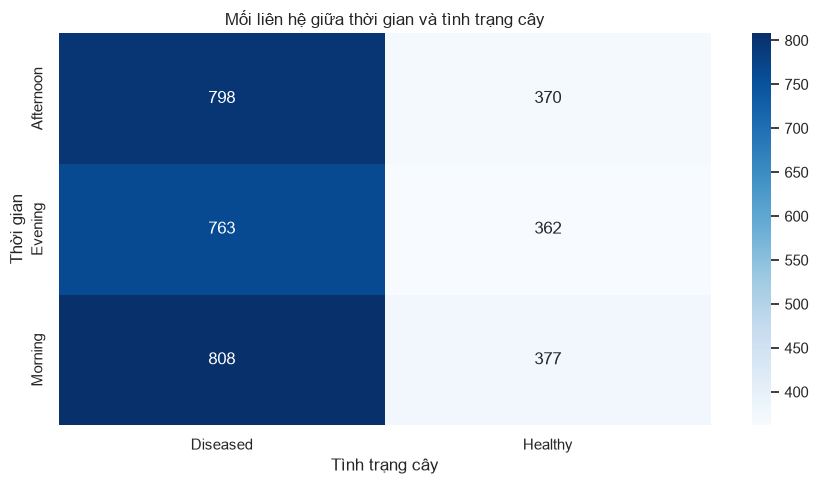

In [37]:
time_health = pd.crosstab(
    df_metadata["Environmental_Conditions.Time_of_Capture"],
    df_metadata["Plant_Health_Status"]
)
display(time_health)

plt.figure(figsize=(9, 5))

sns.heatmap(
    time_health,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Mối liên hệ giữa thời gian và tình trạng cây")
plt.xlabel("Tình trạng cây")
plt.ylabel("Thời gian")

plt.tight_layout()
plt.show()

- Tỷ lệ cây bệnh gần như bằng nhau ở mọi thời điểm chụp: Afternoon 798/1168 (≈68,3%), Evening 763/1125 (≈67,8%), Morning 808/1185 (≈68,2%).
- **Thời điểm chụp gần như không liên quan đến tình trạng cây** (chi-square ở mục 8.6: p = 0,97).

8.5.4 phân bố các loại bệnh ở các vườn (Vineyard x Disease_Type)

Disease_Type,Black Rot,Esca,Healthy,Leaf Blight
Location.Vineyard,,,,
Vineyard_1,14 (12.84%),34 (31.19%),38 (34.86%),23 (21.1%)
Vineyard_2,24 (19.67%),33 (27.05%),39 (31.97%),26 (21.31%)
Vineyard_3,33 (26.83%),37 (30.08%),32 (26.02%),21 (17.07%)
Vineyard_4,23 (18.25%),27 (21.43%),43 (34.13%),33 (26.19%)
Vineyard_5,27 (21.26%),34 (26.77%),43 (33.86%),23 (18.11%)
Vineyard_6,21 (16.28%),27 (20.93%),48 (37.21%),33 (25.58%)
Vineyard_7,24 (22.43%),27 (25.23%),34 (31.78%),22 (20.56%)
Vineyard_8,34 (26.15%),37 (28.46%),30 (23.08%),29 (22.31%)
Vineyard_9,25 (20.0%),28 (22.4%),48 (38.4%),24 (19.2%)


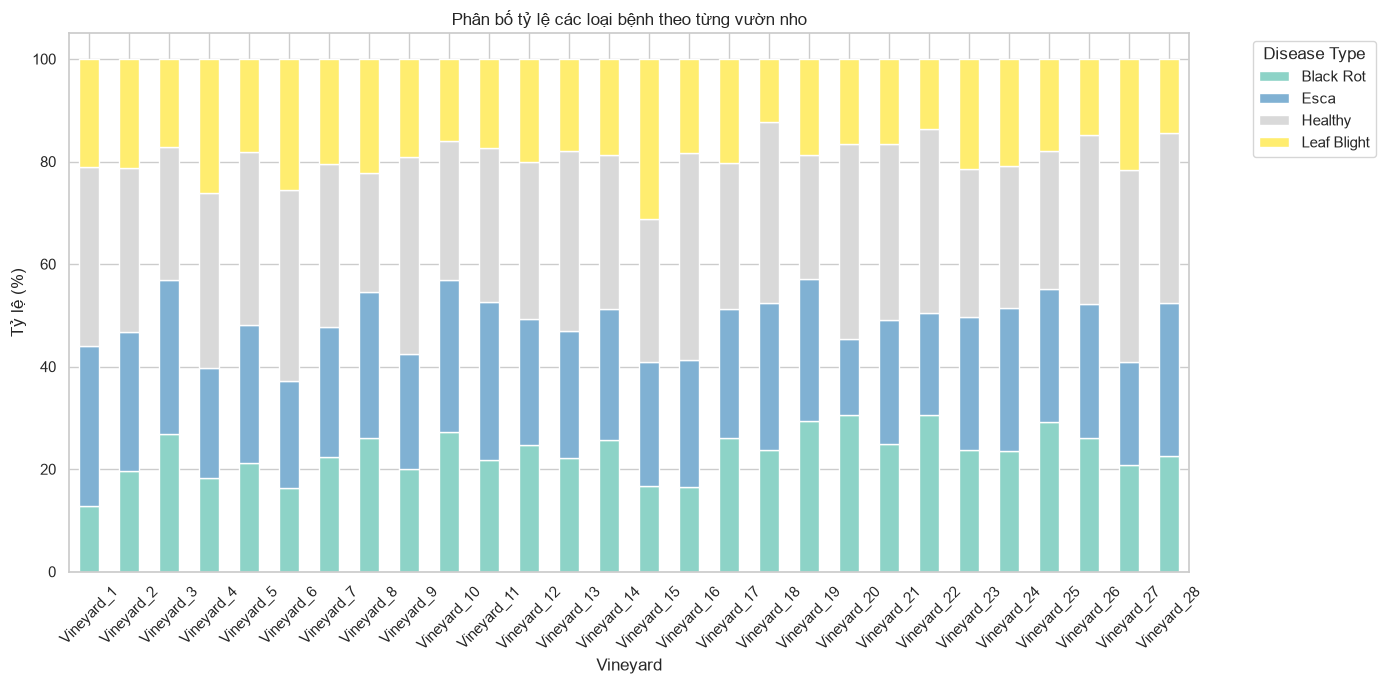

In [38]:
# Bảng tỷ lệ (%)
# Bảng số lượng
df_vineyard_count = pd.crosstab(
    df_metadata["Location.Vineyard"],
    df_metadata["Disease_Type"]
).sort_index(
    key=lambda x: x.str.extract(r'(\d+)')[0].astype(int)
)

# Bảng tỷ lệ (%)
df_vineyard_percent = pd.crosstab(
    df_metadata["Location.Vineyard"],
    df_metadata["Disease_Type"],
    normalize="index"
).sort_index(
    key=lambda x: x.str.extract(r'(\d+)')[0].astype(int)
) * 100

# Gộp số lượng và tỷ lệ
df_vineyard_summary = (
    df_vineyard_count.astype(str)
    + " ("
    + df_vineyard_percent.round(2).astype(str)
    + "%)"
)

display(df_vineyard_summary)

# Trực quan hóa tỷ lệ %
ax = df_vineyard_percent.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 7),
    colormap="Set3"
)

plt.title("Phân bố tỷ lệ các loại bệnh theo từng vườn nho")
plt.xlabel("Vineyard")
plt.ylabel("Tỷ lệ (%)")
plt.xticks(rotation=45)
plt.legend(title="Disease Type", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

> - Tỷ lệ các lớp ở từng vườn dao động quanh mức chung của toàn bộ dữ liệu, không có vườn nào bị thiếu hẳn một lớp.
> - Một số điểm đáng chú ý:
>   - Healthy cao nhất ở Vineyard_16 (40,37%), thấp nhất ở Vineyard_8 (23,08%).
>   - Leaf Blight nổi bật ở Vineyard_15 (31,2%, vườn duy nhất có Leaf Blight cao hơn hẳn Healthy), thấp nhất ở Vineyard_18 (12,3%).
>   - Esca thấp bất thường ở Vineyard_20 (14,81%).
>   - Black Rot thấp nhất ở Vineyard_1 (12,84%) và cao nhất ở Vineyard_22 (30,53%).
> - Mỗi vườn chỉ có khoảng 107–144 mẫu nên các chênh lệch này có thể chỉ là dao động ngẫu nhiên. Cần kiểm định thống kê (ví dụ chi-square) trước khi kết luận vườn nào dễ bị bệnh hơn.

8.5.5 phân bố theo điều kiện thời tiết (Weather x Disease_Type)

Count                           \
Disease_Type                     Black Rot Esca Healthy Leaf Blight   
Environmental_Conditions.Weather                                      
Clear                                  285  288     361         207   
Humid                                  257  288     366         249   
Windy                                  267  312     382         216   

                                 Percentage (%)                             
Disease_Type                          Black Rot   Esca Healthy Leaf Blight  
Environmental_Conditions.Weather                                            
Clear                                     24.98  25.24   31.64       18.14  
Humid                                     22.16  24.83   31.55       21.47  
Windy                                     22.68  26.51   32.46       18.35

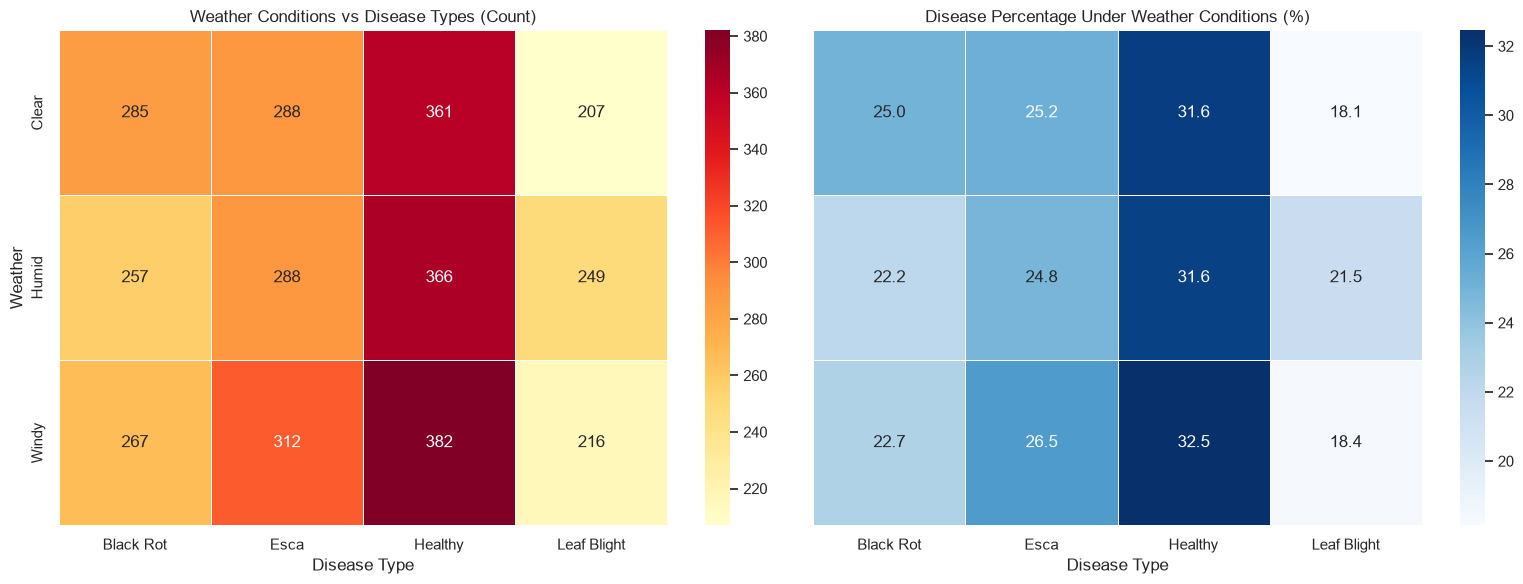

In [39]:
def analyze_weather_disease(df, weather_col="Environmental_Conditions.Weather", disease_col="Disease_Type"):
    # 1. Tính toán số lượng và tỷ lệ phần trăm
    df_count = pd.crosstab(df[weather_col], df[disease_col])
    df_percent = df_count.div(df_count.sum(axis=1), axis=0) * 100

    # Gộp 2 bảng thành 1 bảng tổng hợp để hiển thị gọn gàng
    df_summary = pd.concat([df_count, df_percent.round(2)], axis=1, keys=["Count", "Percentage (%)"])
    display(df_summary)

    # 2. Vẽ 2 biểu đồ cạnh nhau (1 hàng, 2 cột)
    fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

    # Biểu đồ 1: Số lượng
    sns.heatmap(df_count, annot=True, fmt="d", cmap="YlOrRd", linewidths=0.5, ax=axes[0])
    axes[0].set_title("Weather Conditions vs Disease Types (Count)")
    axes[0].set_xlabel("Disease Type")
    axes[0].set_ylabel("Weather")

    # Biểu đồ 2: Phần trăm
    sns.heatmap(df_percent, annot=True, fmt=".1f", cmap="Blues", linewidths=0.5, ax=axes[1])
    axes[1].set_title("Disease Percentage Under Weather Conditions (%)")
    axes[1].set_xlabel("Disease Type")
    axes[1].set_ylabel("") # Ẩn nhãn trục Y bên phải vì đã dùng chung với bên trái

    plt.tight_layout()
    plt.show()

# Gọi hàm chạy
analyze_weather_disease(df_metadata)

> - Tỷ lệ từng lớp ở các loại thời tiết khá gần nhau:
>   - Healthy: 31,5 – 32,5%
>   - Esca: 24,8 – 26,5%
>   - Black Rot: 22,2 – 25,0% (cao nhất ở Clear)
>   - Leaf Blight: 18,1 – 21,5% (cao nhất ở Humid)
> - Chênh lệch lớn nhất chỉ khoảng 3 điểm phần trăm (Leaf Blight ở Humid so với Clear). Có xu hướng nhẹ rằng thời tiết ẩm thì Leaf Blight nhiều hơn, nhưng chưa đủ mạnh để kết luận.
> - Nhìn chung **thời tiết không phải yếu tố phân biệt rõ ràng** giữa các loại bệnh.

8.5.6 GPS x Disease_Type

Số lượng mẫu có GPS hợp lệ: 3478

--- Phân bố theo tọa độ (Top 10) ---


,Disease_Type,Black Rot,Esca,Healthy,Leaf Blight
Location.GPS.Latitude,Location.GPS.Longitude,,,,
18.731029,73.977206,28,37,41,18
18.734004,74.054693,34,37,34,20
18.735187,74.005753,18,27,44,20
18.742834,74.051588,26,29,41,21
18.744878,74.018640,29,35,43,15
18.750256,73.990160,32,31,35,25
18.753966,74.028567,39,35,36,24
18.759723,74.052451,33,33,41,27
18.770889,74.024265,23,27,43,33



--- Thống kê theo từng vườn nho ---


,Location.Vineyard,Disease_Type,Sample_Count,Average_Latitude,Average_Longitude
0,Vineyard_1,Black Rot,14,18.810208,73.989924
1,Vineyard_1,Esca,34,18.810208,73.989924
2,Vineyard_1,Healthy,38,18.810208,73.989924
3,Vineyard_1,Leaf Blight,23,18.810208,73.989924
4,Vineyard_10,Black Rot,34,18.734004,74.054693
...,...,...,...,...,...
107,Vineyard_8,Leaf Blight,29,18.790580,74.002429
108,Vineyard_9,Black Rot,25,18.798335,74.046139
109,Vineyard_9,Esca,28,18.798335,74.046139
110,Vineyard_9,Healthy,48,18.798335,74.046139


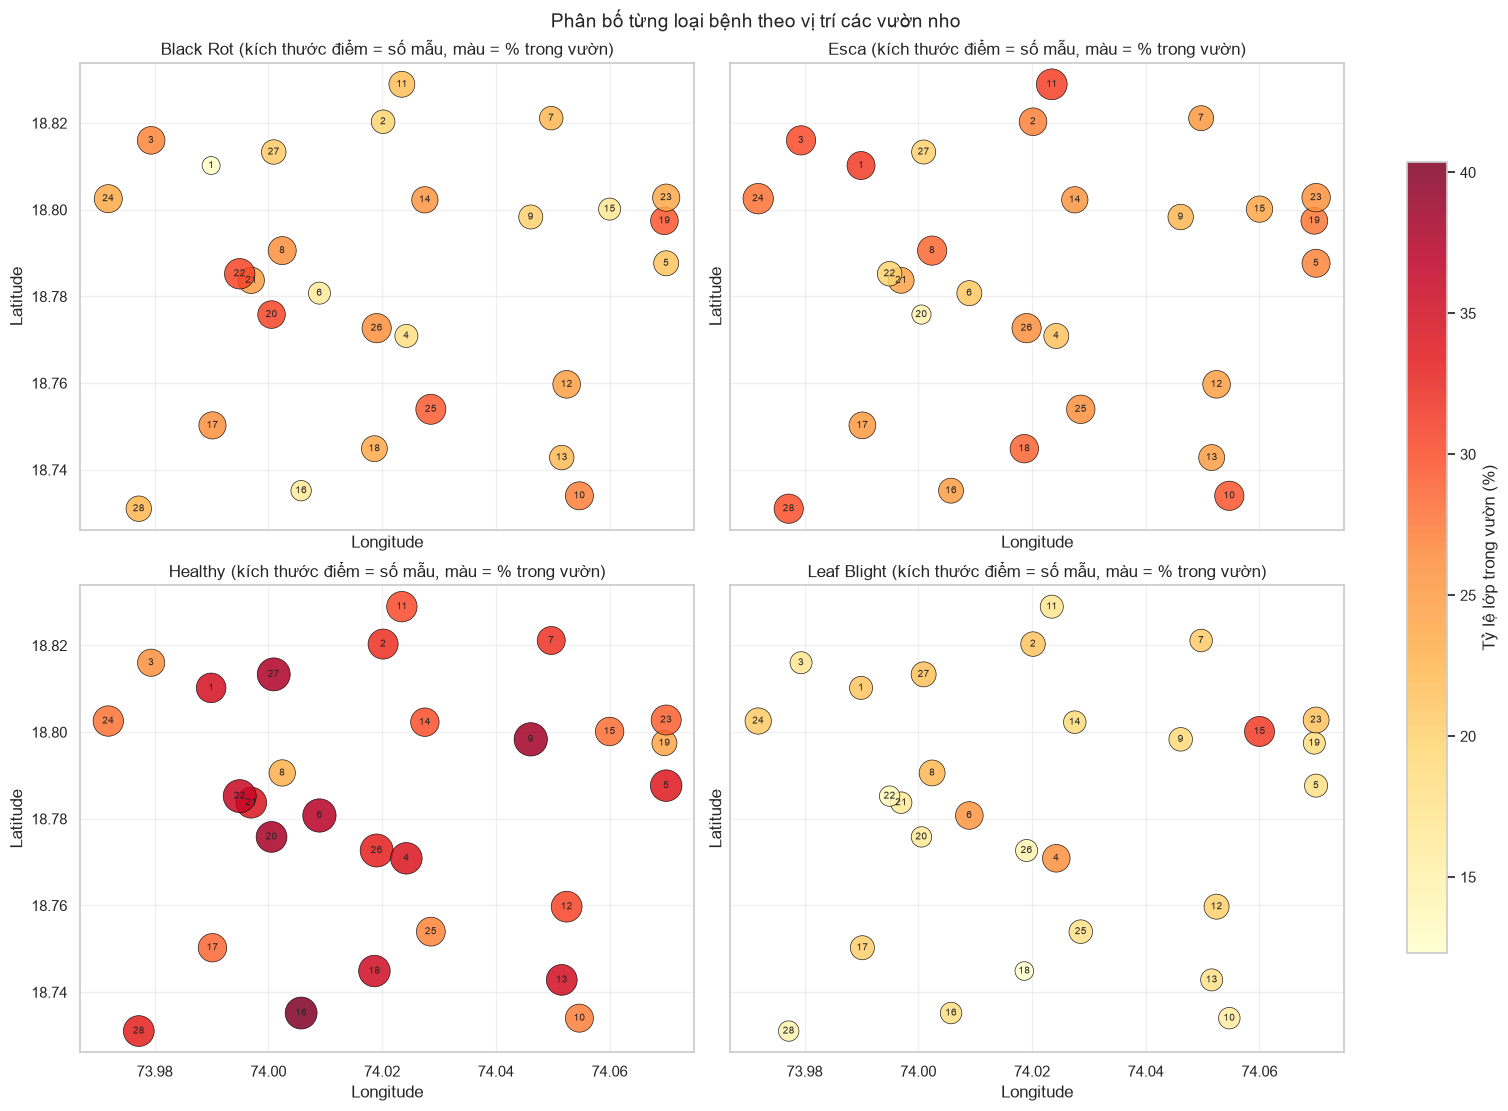

In [40]:
def analyze_gps_disease(df):
    # 1. Trích xuất, ép kiểu số và lọc bỏ giá trị thiếu gọn trong 1 bước
    cols = ["Location.GPS.Latitude", "Location.GPS.Longitude", "Disease_Type", "Location.Vineyard"]
    df_gps = df[cols].copy()
    
    for col in ["Location.GPS.Latitude", "Location.GPS.Longitude"]:
        df_gps[col] = pd.to_numeric(df_gps[col], errors="coerce")
        
    df_gps = df_gps.dropna(subset=["Location.GPS.Latitude", "Location.GPS.Longitude", "Disease_Type"])
    print(f"Số lượng mẫu có GPS hợp lệ: {len(df_gps)}")

    # 2. Thống kê theo tọa độ & theo từng vườn
    df_gps_dist = pd.crosstab([df_gps["Location.GPS.Latitude"], df_gps["Location.GPS.Longitude"]], df_gps["Disease_Type"])
    
    df_vineyard_gps = df_gps.groupby(["Location.Vineyard", "Disease_Type"]).agg(
        Sample_Count=("Disease_Type", "count"),
        Average_Latitude=("Location.GPS.Latitude", "mean"),
        Average_Longitude=("Location.GPS.Longitude", "mean")
    ).reset_index()

    print("\n--- Phân bố theo tọa độ (Top 10) ---")
    display(df_gps_dist.head(10))
    print("\n--- Thống kê theo từng vườn nho ---")
    display(df_vineyard_gps)

    # 3. Trực quan hóa: tách riêng từng lớp bệnh để các điểm cùng vườn không chồng lên nhau
    df_plot = df_vineyard_gps.copy()
    df_plot["Percent"] = (
        df_plot["Sample_Count"]
        / df_plot.groupby("Location.Vineyard")["Sample_Count"].transform("sum")
        * 100
    )
    diseases = sorted(df_plot["Disease_Type"].unique())
    vmin, vmax = df_plot["Percent"].min(), df_plot["Percent"].max()

    fig, axes = plt.subplots(2, 2, figsize=(15, 11), sharex=True, sharey=True, constrained_layout=True)

    for ax, disease in zip(axes.ravel(), diseases):
        sub = df_plot[df_plot["Disease_Type"] == disease]
        sc = ax.scatter(
            sub["Average_Longitude"], sub["Average_Latitude"],
            s=sub["Sample_Count"] * 12, c=sub["Percent"], cmap="YlOrRd",
            vmin=vmin, vmax=vmax, alpha=0.85, edgecolor="black", linewidth=0.5
        )
        # Ghi số thứ tự vườn lên từng điểm
        for _, r in sub.iterrows():
            ax.annotate(
                r["Location.Vineyard"].split("_")[-1],
                (r["Average_Longitude"], r["Average_Latitude"]),
                fontsize=7, ha="center", va="center"
            )
        ax.set_title(f"{disease} (kích thước điểm = số mẫu, màu = % trong vườn)")
        ax.set_xlabel("Longitude")
        ax.set_ylabel("Latitude")
        ax.grid(alpha=0.3)

    fig.colorbar(sc, ax=axes, label="Tỷ lệ lớp trong vườn (%)", shrink=0.8)
    fig.suptitle("Phân bố từng loại bệnh theo vị trí các vườn nho", fontsize=14)
    plt.show()

    return df_gps, df_vineyard_gps

# Gọi hàm
df_gps_clean, df_vineyard_summary = analyze_gps_disease(df_metadata)

> - Cả 3.478 mẫu đều có GPS hợp lệ. Chỉ có **28 tọa độ khác nhau**, tương ứng với 28 vườn, tức mỗi vườn dùng đúng một tọa độ chung cho mọi mẫu.
> - Các vườn nằm trong vùng khoảng vĩ độ 18,73–18,83 và kinh độ 73,97–74,07.
> - Do đó GPS không cung cấp thêm thông tin ngoài mã vườn, và không thấy cụm bệnh nào theo vị trí địa lý.
> - Biểu đồ vẽ lại (tách từng loại bệnh) đã đọc được: các vườn có tỷ lệ cao hoặc thấp nằm rải rác, không tạo thành cụm theo vùng. Ví dụ Leaf Blight nổi bật ở Vineyard_15 nhưng các vườn lân cận (5, 19, 23) không cao, còn Healthy cao ở nhiều vườn nằm xa nhau (16, 9, 20, 27). Bệnh không phân bố theo vị trí địa lý.

8.6 Kiểm định chi-square

In [41]:
from scipy.stats import chi2_contingency

env_cols = [
    "Environmental_Conditions.Weather",
    "Environmental_Conditions.Lighting",
    "Environmental_Conditions.Time_of_Capture",
    "Location.Vineyard",
]
targets = ["Plant_Health_Status", "Disease_Type"]

rows = []
for col in env_cols:
    for target in targets:
        table = pd.crosstab(df_metadata[col], df_metadata[target])
        chi2, p_value, dof, _ = chi2_contingency(table)
        n = table.values.sum()
        # Cramér's V: mức độ liên hệ (0 = không liên hệ, 1 = liên hệ hoàn toàn)
        cramers_v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
        rows.append({
            "Thuoc_tinh": col,
            "Bien_muc_tieu": target,
            "Chi2": round(chi2, 3),
            "Bac_tu_do": dof,
            "p_value": round(p_value, 4),
            "Cramers_V": round(cramers_v, 4),
            "Co_y_nghia (p<0.05)": p_value < 0.05,
        })

chi_result = pd.DataFrame(rows)
display(chi_result)

,Thuoc_tinh,Bien_muc_tieu,Chi2,Bac_tu_do,p_value,Cramers_V,Co_y_nghia (p<0.05)
0,Environmental_Conditions.Weather,Plant_Health_Status,0.267,2,0.8748,0.0088,False
1,Environmental_Conditions.Weather,Disease_Type,7.263,6,0.2972,0.0323,False
2,Environmental_Conditions.Lighting,Plant_Health_Status,0.472,2,0.7898,0.0116,False
3,Environmental_Conditions.Lighting,Disease_Type,5.488,6,0.4830,0.0281,False
4,Environmental_Conditions.Time_of_Capture,Plant_Health_Status,0.070,2,0.9655,0.0045,False
5,Environmental_Conditions.Time_of_Capture,Disease_Type,5.517,6,0.4794,0.0282,False
6,Location.Vineyard,Plant_Health_Status,31.271,27,0.2602,0.0948,False
7,Location.Vineyard,Disease_Type,95.104,81,0.1354,0.0955,False


- Cả 8 cặp thuộc tính đều có p > 0,05 (nhỏ nhất là Vineyard × Disease_Type với p = 0,135), nên **không có mối liên hệ có ý nghĩa thống kê** giữa thời tiết, ánh sáng, thời điểm chụp hay vườn với tình trạng cây và loại bệnh.
- Cramér's V đều rất nhỏ (từ 0,0045 đến 0,0955), mạnh nhất cũng chỉ khoảng 0,095 ở cột vườn, tức mức liên hệ không đáng kể.
- Vì vậy các chênh lệch đã thấy ở 8.5.4 và 8.5.5 (Leaf Blight cao ở Vineyard_15, Esca thấp ở Vineyard_20, Leaf Blight nhiều hơn khi trời ẩm) nhiều khả năng chỉ là dao động ngẫu nhiên.
- Kiểm định chỉ cho thấy không đủ bằng chứng về mối liên hệ, chứ không chứng minh là hoàn toàn không có. Tuy vậy, metadata có vẻ ít giá trị để phân loại bệnh, mô hình nhiều khả năng phải dựa vào nội dung ảnh.

**9.CHUẨN BỊ DỮ LIỆU CHO MÔ HÌNH**

9.1 Loại bỏ các cột không dùng làm feature

In [42]:
# Kiểm tra các cột thiết bị có thật sự không đổi không
device_cols = [c for c in df_metadata.columns if c.startswith("Device_Specifications.")]
print("Số giá trị khác nhau của các cột thiết bị:")
print(df_metadata[device_cols].nunique())

# Bỏ Plant_Health_Status (rò rỉ nhãn) và các cột thiết bị (không đổi)
drop_cols = ["Plant_Health_Status"] + device_cols
df_model = df_metadata_clean.drop(columns=drop_cols)

print("\nĐã bỏ:", drop_cols)
print("Các cột còn lại:", df_model.columns.tolist())

Số giá trị khác nhau của các cột thiết bị:
Device_Specifications.Device_Name    1
Device_Specifications.Sensor         1
Device_Specifications.OS             1
dtype: int64

Đã bỏ: ['Plant_Health_Status', 'Device_Specifications.Device_Name', 'Device_Specifications.Sensor', 'Device_Specifications.OS']
Các cột còn lại: ['Sr_No', 'Disease_Type', 'Location.Vineyard', 'Location.GPS.Latitude', 'Location.GPS.Longitude', 'Environmental_Conditions.Time_of_Capture', 'Environmental_Conditions.Lighting', 'Environmental_Conditions.Weather']


- Cả 3 cột thiết bị (`Device_Name`, `Sensor`, `OS`) đều chỉ có 1 giá trị duy nhất, xác nhận có thể bỏ an toàn.
- Đã bỏ 4 cột (`Plant_Health_Status` và 3 cột thiết bị), còn lại 8 cột: `Sr_No`, nhãn `Disease_Type`, vườn, 2 cột GPS và 3 cột điều kiện chụp.
- `Sr_No` chỉ là mã định danh và GPS chỉ lặp lại thông tin của vườn, nên cũng không cần dùng làm feature.

9.2 Chia train/val/test theo stratified split

In [43]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

# Chia 70% train / 15% val / 15% test, giữ nguyên tỷ lệ các lớp (stratified)
train_idx, temp_idx = train_test_split(
    df_model.index, test_size=0.30,
    stratify=df_model["Disease_Type"], random_state=RANDOM_STATE
)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50,
    stratify=df_model.loc[temp_idx, "Disease_Type"], random_state=RANDOM_STATE
)

splits_stratified = {"train": train_idx, "val": val_idx, "test": test_idx}


def summarize_split(splits):
    """Số mẫu và tỷ lệ (%) từng lớp trong mỗi tập."""
    count = pd.DataFrame({
        name: df_model.loc[idx, "Disease_Type"].value_counts()
        for name, idx in splits.items()
    }).T
    percent = count.div(count.sum(axis=1), axis=0) * 100
    return pd.concat([count, percent.round(2)], axis=1, keys=["Count", "Percentage (%)"])


display(summarize_split(splits_stratified))

Count                            Percentage (%)         \
Disease_Type Healthy Esca Black Rot Leaf Blight        Healthy   Esca   
train            776  622       565         470          31.89  25.57   
val              166  133       121         101          31.86  25.53   
test             167  133       121         101          31.99  25.48   

                                    
Disease_Type Black Rot Leaf Blight  
train            23.22       19.32  
val              23.22       19.39  
test             23.18       19.35

- 3.478 mẫu được chia thành train 2.434, val 522 và test 522 (đúng 70/15/15).
- Tỷ lệ các lớp ở cả 3 tập gần như giống hệt nhau và giống toàn bộ dữ liệu (Healthy ≈31,8–32,0%, Esca ≈25,5%, Black Rot ≈23,2–23,4%, Leaf Blight ≈19,3–19,4%), nên stratified split hoạt động tốt.
- Đây là chia ngẫu nhiên theo mẫu nên ảnh cùng vườn có thể nằm ở cả train và test.
- ⚠️ Cách chia này làm trên bản ghi metadata, **chưa tính đến ảnh trùng** (xem mục kiểm tra ảnh trùng ở phần 7). Khi chia cho ảnh phải chia theo nhóm trùng hoặc loại trùng trước, nếu không bản sao của cùng một ảnh có thể nằm ở cả train và test.

9.3 Chia theo vườn (group split)

In [44]:
from sklearn.model_selection import StratifiedGroupKFold

groups = df_model["Location.Vineyard"]

# Tách test: 5 fold -> 1 fold làm test (~20%), các vườn ở test không xuất hiện ở tập còn lại
sgkf_test = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
trainval_pos, test_pos = next(sgkf_test.split(df_model, df_model["Disease_Type"], groups))
df_trainval = df_model.iloc[trainval_pos]

# Tách val từ phần còn lại: 4 fold -> 1 fold làm val (~20% tổng)
sgkf_val = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)
train_pos, val_pos = next(sgkf_val.split(df_trainval, df_trainval["Disease_Type"], df_trainval["Location.Vineyard"]))

splits_group = {
    "train": df_trainval.index[train_pos],
    "val": df_trainval.index[val_pos],
    "test": df_model.index[test_pos],
}

# Kiểm tra không có vườn nào xuất hiện ở hai tập khác nhau
vineyards = {name: set(df_model.loc[idx, "Location.Vineyard"]) for name, idx in splits_group.items()}
print("Trùng vườn train & val :", vineyards["train"] & vineyards["val"])
print("Trùng vườn train & test:", vineyards["train"] & vineyards["test"])
print("Trùng vườn val & test  :", vineyards["val"] & vineyards["test"])
print("Số vườn mỗi tập:", {k: len(v) for k, v in vineyards.items()})

display(summarize_split(splits_group))

Trùng vườn train & val : set()
Trùng vườn train & test: set()
Trùng vườn val & test  : set()
Số vườn mỗi tập: {'train': 17, 'val': 5, 'test': 6}


Count                          Percentage (%)                 \
Disease_Type Black Rot Esca Healthy Leaf Blight      Black Rot   Esca Healthy   
train              516  550     669         397          24.20  25.80   31.38   
val                111  158     201         132          18.44  26.25   33.39   
test               180  180     239         143          24.26  24.26   32.21   

                          
Disease_Type Leaf Blight  
train              18.62  
val                21.93  
test               19.27

- Không có vườn nào xuất hiện ở hai tập khác nhau (train 16 vườn, val 6 vườn, test 6 vườn), nên không bị lẫn vườn giữa các tập.
- Số mẫu: train 1.998 (≈57,4%), val 738 (≈21,2%), test 742 (≈21,3%). Hơi lệch so với 60/20/20 vì các vườn có số mẫu khác nhau.
- Tỷ lệ lớp kém đều hơn stratified split: Black Rot là 22,17% ở train nhưng 25,20% ở val, Leaf Blight là 19,72% ở train và 18,29% ở val. Chênh lệch dưới khoảng 3 điểm phần trăm, vẫn chấp nhận được.
- Cách chia này phản ánh sát hơn việc áp dụng mô hình cho vườn mới. Nên so sánh kết quả với stratified split để biết mô hình có bị đánh giá quá lạc quan hay không.

9.4 Tính class weight cho các lớp

In [45]:
from sklearn.utils.class_weight import compute_class_weight

# Tính trọng số lớp trên tập train (lớp càng ít mẫu thì trọng số càng lớn)
y_train = df_model.loc[splits_stratified["train"], "Disease_Type"]
classes = np.sort(y_train.unique())
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)

class_weights = {c: round(float(w), 3) for c, w in zip(classes, weights)}
print("Class weights:", class_weights)

Class weights: {'Black Rot': 1.077, 'Esca': 0.978, 'Healthy': 0.784, 'Leaf Blight': 1.294}


- Trọng số: Leaf Blight 1,295 > Black Rot 1,075 > Esca 0,978 > Healthy 0,784. Lớp càng ít mẫu thì trọng số càng lớn, Leaf Blight gấp khoảng 1,65 lần Healthy, đúng với mức mất cân bằng đã thấy.
- Các trọng số đều gần 1 (0,78–1,30), xác nhận mất cân bằng chỉ ở mức nhẹ, class weight là đủ và chưa cần oversampling mạnh.
- Trọng số được tính trên tập train của stratified split.

**10.TỔNG KẾT**

**Phân bố nhãn**
- Healthy 31,89%, Esca 25,53%, Black Rot 23,26%, Leaf Blight 19,32%. Dữ liệu mất cân bằng nhẹ (lớp lớn nhất gấp khoảng 1,65 lần lớp nhỏ nhất).
- Xét theo tình trạng: 68,11% Diseased và 31,89% Healthy.

**Chất lượng dữ liệu**
- Không có giá trị thiếu, không có chuỗi rỗng, không có bản ghi trùng, không trùng `Sr_No`.
- Nhãn phân loại sạch, không có biến thể chính tả.
- GPS hợp lệ 100% (không có tọa độ ngoài phạm vi hay sai định dạng).
- Không có ảnh hỏng hay kích thước không hợp lệ. Mọi ảnh đều là JPEG 1080×1080.
- **Có ảnh trùng nội dung** (kiểm tra bằng MD5, xem mục 7): số liệu chi tiết ở mục đó; việc xử lý thực hiện ở 03_Image_Preprocessing.

**Phân tích metadata**
- 28 vườn có số mẫu khá đồng đều (107–144 mẫu/vườn).
- Thời điểm chụp, ánh sáng và thời tiết đều chia gần đều thành 3 nhóm.
- Thời tiết gần như không liên quan đến tình trạng cây (tỷ lệ bệnh ≈ 67,5–68,4% ở cả 3 loại). Với từng loại bệnh, chênh lệch theo thời tiết chỉ khoảng 3 điểm phần trăm, với xu hướng nhẹ là Leaf Blight nhiều hơn khi trời ẩm.
- Phân bố bệnh theo vườn có vài điểm lệch (ví dụ Leaf Blight cao ở Vineyard_15, Esca thấp ở Vineyard_20), nhưng cỡ mẫu mỗi vườn nhỏ nên chưa đủ để kết luận.
- GPS chỉ có 28 tọa độ khác nhau, mỗi vườn một tọa độ, nên không mang thêm thông tin ngoài mã vườn và không thấy cụm bệnh theo không gian.
- `Plant_Health_Status` được suy ra từ `Disease_Type`, còn thông tin thiết bị không đổi giữa các mẫu, nên cả hai cột đều không có giá trị làm feature.